# Dá Pra Ir? | Inteligência Artificial & Machine Learning

Global Solution FIAP 2026, tema CitizenTech.

## 1. Problema e pergunta de ML

O Dá Pra Ir? ajuda pessoas com deficiência, pessoas autistas e famílias atípicas a saber, antes de sair de casa, se um lugar vai funcionar para elas. Nosso recorte é a Vila Clementino (subprefeitura Vila Mariana), em São Paulo, onde ficam a AACD, o Hospital do Servidor Público Estadual e o Hospital São Paulo (Unifesp).

A parte de ML tenta responder duas perguntas com dados públicos. O Modelo A ("Quando ir?") prevê quantas pessoas vão entrar por dia nas estações AACD-Servidor e Hospital São Paulo, da Linha 5-Lilás. Menos gente quer dizer menos barulho e menos multidão. O Modelo B ("Tá funcionando?") prevê se um chamado de calçada, rampa ou obstáculo feito no SP156 vai ser resolvido em até 30 dias.

Nos dois usamos XGBoost e comparamos com Random Forest. Treinamos com 2024 e testamos com 2025.

## 2. Dados (download e leitura)

Usamos três fontes públicas: as entradas diárias por estação do Metrô (organizadas pelo pacote metrosp), os chamados do SP156 da Prefeitura e os dados horários da estação A701 do INMET, no Mirante de Santana.

Os arquivos originais vão para `dados/brutos/`, que não sobe para o GitHub. Se um arquivo já estiver lá, o notebook não baixa de novo. Os dados filtrados ficam em `dados/`.

In [1]:
import os
import zipfile
from datetime import date

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyreadr
import requests
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor

PASTA_DADOS = 'dados'
PASTA_BRUTOS = os.path.join(PASTA_DADOS, 'brutos')

os.makedirs(PASTA_BRUTOS, exist_ok=True)

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', None)

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
    'axes.edgecolor': '#8a8984', 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.axisbelow': True,
})
AZUL, LARANJA = '#2a78d6', '#eb6834'

In [2]:
def baixar(url, caminho):
    if os.path.exists(caminho):
        print('Já existe, não vou baixar de novo:', caminho)
        return
    print('Baixando:', url)
    resposta = requests.get(url, stream=True, timeout=120)
    resposta.raise_for_status()
    temporario = caminho + '.parcial'
    with open(temporario, 'wb') as f:
        for bloco in resposta.iter_content(chunk_size=1024 * 1024):
            f.write(bloco)
    os.replace(temporario, caminho)
    print('Salvo em:', caminho)

### 2.1 Metrô SP

O pacote metrosp junta os dados do Metrô e do Insper Dataverse numa tabela de entradas por dia e por estação. O arquivo vem no formato do R (`.rds`), por isso usamos a biblioteca `pyreadr` para ler. Como o autor atualiza esse arquivo de vez em quando, os números podem mudar um pouco de um download para outro.

In [3]:
URL_METRO = 'https://github.com/viniciusoike/metrosp/releases/download/data-latest/station_entries_daily.rds'
ARQ_METRO = os.path.join(PASTA_BRUTOS, 'station_entries_daily.rds')

baixar(URL_METRO, ARQ_METRO)

Já existe, não vou baixar de novo: dados\brutos\station_entries_daily.rds


### 2.2 SP156

O SP156 publica um CSV por trimestre, cada um com mais de 100 MB. Baixamos os 8 trimestres de 2024 e 2025.

In [4]:
BASE_SP156 = 'https://dados.prefeitura.sp.gov.br/dataset/0aecfa2b-aa3a-40d4-8183-0d4351b7fd0a/resource/'
URLS_SP156 = {
    'sp156_2024_t1.csv': BASE_SP156 + '787c054d-3e77-46c8-8713-e4e26eb2dd55/download/arquivo-final-1-trim.-2024.csv',
    'sp156_2024_t2.csv': BASE_SP156 + '2d020379-fa40-4dc0-8d17-add74b119550/download/arquivo-final-2-trim.-2024.csv',
    'sp156_2024_t3.csv': BASE_SP156 + '3c12fe0a-ec4f-4a20-a987-dd177330f4ce/download/arquivo-final-3-trim.-2024.csv',
    'sp156_2024_t4.csv': BASE_SP156 + 'ed357147-f15c-4bf0-ad15-edc963a9f130/download/arquivo-final-4-trim.-2024.csv',
    'sp156_2025_t1.csv': BASE_SP156 + '7c5aeb58-2cad-40ba-9e9e-af1c17cc5070/download/arquivo-final-1-trim-25.csv',
    'sp156_2025_t2.csv': BASE_SP156 + 'f5df7f4a-d614-4f85-b4a0-263ec9370cd9/download/arquivo-final-2-trim-25.csv',
    'sp156_2025_t3.csv': BASE_SP156 + '3b1d2648-d586-40c8-819c-24fbb8005343/download/arquivo-final-3-trim-25.csv',
    'sp156_2025_t4.csv': BASE_SP156 + 'd3a98097-8128-45d4-b8fe-21874b81c971/download/arquivo-final-4-trim-25.csv',
}

for nome, url in URLS_SP156.items():
    baixar(url, os.path.join(PASTA_BRUTOS, nome))

Já existe, não vou baixar de novo: dados\brutos\sp156_2024_t1.csv
Já existe, não vou baixar de novo: dados\brutos\sp156_2024_t2.csv
Já existe, não vou baixar de novo: dados\brutos\sp156_2024_t3.csv
Já existe, não vou baixar de novo: dados\brutos\sp156_2024_t4.csv
Já existe, não vou baixar de novo: dados\brutos\sp156_2025_t1.csv
Já existe, não vou baixar de novo: dados\brutos\sp156_2025_t2.csv
Já existe, não vou baixar de novo: dados\brutos\sp156_2025_t3.csv
Já existe, não vou baixar de novo: dados\brutos\sp156_2025_t4.csv


### 2.3 INMET

O INMET publica um ZIP por ano com todas as estações, e nós usamos só a A701. Se o download pelo notebook não funcionar, baixe os arquivos no site do INMET e coloque em `ml/dados/brutos/`.

In [5]:
for ano in [2024, 2025]:
    caminho = os.path.join(PASTA_BRUTOS, f'{ano}.zip')
    try:
        baixar(f'https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip', caminho)
    except requests.RequestException as erro:
        print(f'Não foi possível baixar o arquivo do INMET de {ano}: {erro}')
        print(f'Baixe manualmente: abra https://portal.inmet.gov.br/dadoshistoricos no navegador,')
        print(f'clique em "{ano}" e salve o arquivo como ml/dados/brutos/{ano}.zip. Depois rode esta célula de novo.')

Já existe, não vou baixar de novo: dados\brutos\2024.zip
Já existe, não vou baixar de novo: dados\brutos\2025.zip


### 2.4 Leitura do Metrô

Ficamos só com as duas estações do recorte. Mantemos também as datas antes de 2024, porque elas entram no cálculo do movimento de 7 e 14 dias antes no começo de 2024.

In [6]:
metro_bruto = list(pyreadr.read_r(ARQ_METRO).values())[0]

ESTACOES = ['AACD-Servidor', 'Hospital São Paulo']
metro = metro_bruto[metro_bruto['station_name'].isin(ESTACOES)]
metro = metro[['date', 'station_name', 'value']]
metro.columns = ['data', 'estacao', 'entradas']
metro['data'] = pd.to_datetime(metro['data'])
metro = metro.sort_values(['estacao', 'data']).reset_index(drop=True)

metro.to_csv(os.path.join(PASTA_DADOS, 'metro_entradas_diarias.csv'), index=False)
metro.head()

,data,estacao,entradas
0,2018-08-31,AACD-Servidor,678.0
1,2018-09-01,AACD-Servidor,763.0
2,2018-09-02,AACD-Servidor,453.0
3,2018-09-03,AACD-Servidor,1867.0
4,2018-09-04,AACD-Servidor,2066.0


### 2.5 Leitura do SP156

Como os CSVs são grandes, lemos cada um em partes e guardamos só os chamados de cinco serviços: manutenção de calçada pública, obstáculo na calçada, calçada particular danificada, pedido de rebaixamento de guia e fiscalização de rebaixamento irregular. Eles saíram de uma busca mais ampla por palavras como calçada, rampa e acessibilidade, da qual tiramos o que não tem a ver com andar na calçada (poda de árvore, sarjeta, pintura de guia, relógios de rua).

Não guardamos as colunas de endereço (logradouro, bairro, número, CEP, latitude e longitude), porque mostram a localização exata de quem reclamou, e o distrito já basta. A pesquisa de satisfação também ficou de fora: ela só existe depois que o chamado é atendido, então usá-la seria vazamento de dados.

O 2º trimestre de 2024 ficou de fora porque o arquivo não tem a coluna Serviço, e sem ela não dá para separar os serviços que queremos. Os arquivos estão em cp1252, e o do 1º trimestre de 2025 termina com linhas vazias, que descartamos.

In [7]:
COLUNAS_SP156 = {
    'Data de Abertura': 'data_abertura',
    'Data de Finalização': 'data_finalizacao',
    'Meio de Comunicação': 'canal',
    'Tema': 'tema',
    'Assunto': 'assunto',
    'Serviço': 'servico',
    'Status': 'status',
    'Órgão': 'orgao',
    'Prefeitura Operacional': 'subprefeitura',
    'Distrito': 'distrito',
}

SERVICOS_MODELO_B = [
    'Calçada pública - solicitar manutenção',
    'Acessibilidade - solicitar avaliação de obstáculo na calçada',
    'Calçada particular - denunciar calçada danificada ou inexistente',
    'Guias para travessia de pedestres - Solicitar rebaixamento',
    'Guia rebaixada - solicitar fiscalização de rebaixamento irregular',
]

CODIFICACAO = 'cp1252'

partes = []
resumo_arquivos = []
for nome in URLS_SP156:
    caminho = os.path.join(PASTA_BRUTOS, nome)
    colunas_arquivo = pd.read_csv(caminho, sep=';', encoding=CODIFICACAO, nrows=0).columns

    if 'Serviço' not in colunas_arquivo:
        total = sum(p['Data de Abertura'].notna().sum()
                    for p in pd.read_csv(caminho, sep=';', encoding=CODIFICACAO, usecols=['Data de Abertura'],
                                         dtype=str, chunksize=200_000))
        resumo_arquivos.append({'arquivo': nome, 'chamados': total, 'chamados_guardados': 0,
                                'observacao': 'sem coluna Serviço, fica de fora'})
        continue

    total = 0
    guardadas = 0
    for parte in pd.read_csv(caminho, sep=';', encoding=CODIFICACAO, usecols=list(COLUNAS_SP156),
                             dtype=str, chunksize=200_000):
        parte = parte.dropna(how='all')
        total += len(parte)
        parte = parte[parte['Serviço'].str.strip().isin(SERVICOS_MODELO_B)]
        guardadas += len(parte)
        partes.append(parte)
    resumo_arquivos.append({'arquivo': nome, 'chamados': total, 'chamados_guardados': guardadas, 'observacao': ''})

sp156 = pd.concat(partes, ignore_index=True).rename(columns=COLUNAS_SP156)
sp156 = sp156[list(COLUNAS_SP156.values())]
sp156['servico'] = sp156['servico'].str.strip()

sp156['data_abertura'] = pd.to_datetime(sp156['data_abertura'], format='%d/%m/%Y', errors='coerce')
sp156['data_finalizacao'] = pd.to_datetime(sp156['data_finalizacao'], format='%d/%m/%Y', errors='coerce')

sp156.to_csv(os.path.join(PASTA_DADOS, 'sp156_acessibilidade.csv'), index=False)
pd.DataFrame(resumo_arquivos)

,arquivo,chamados,chamados_guardados,observacao
0,sp156_2024_t1.csv,611565,4351,
1,sp156_2024_t2.csv,511779,0,"sem coluna Serviço, fica de fora"
2,sp156_2024_t3.csv,466543,3388,
3,sp156_2024_t4.csv,576794,3187,
4,sp156_2025_t1.csv,742904,4372,
5,sp156_2025_t2.csv,589980,3777,
6,sp156_2025_t3.csv,501685,3667,
7,sp156_2025_t4.csv,479701,3648,


### 2.6 Leitura do INMET

O INMET mede de hora em hora, no horário UTC. Passamos para o horário de Brasília (3 horas a menos) para o dia do clima bater com o dia do metrô, e depois juntamos por dia: chuva total, temperatura máxima e umidade média. Horas sem medição (valor -9999) ficam vazias. Por causa do fuso, o 31/12/2025 fica sem as 3 últimas horas, e o 31/12/2023 aparece com só 3 horas, então ele sai.

In [8]:
COLUNAS_INMET = {
    'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)': 'chuva_mm',
    'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)': 'temp_max_c',
    'UMIDADE RELATIVA DO AR, HORARIA (%)': 'umidade_pct',
}

partes = []
for ano in [2024, 2025]:
    with zipfile.ZipFile(os.path.join(PASTA_BRUTOS, f'{ano}.zip')) as z:
        nome_a701 = [n for n in z.namelist() if 'A701' in n][0]
        with z.open(nome_a701) as f:
            partes.append(pd.read_csv(f, sep=';', skiprows=8, encoding='latin1', decimal=','))
inmet_horario = pd.concat(partes, ignore_index=True)

inmet_horario = inmet_horario.rename(columns=COLUNAS_INMET)
inmet_horario = inmet_horario[['Data', 'Hora UTC'] + list(COLUNAS_INMET.values())]
inmet_horario = inmet_horario.replace(-9999, np.nan)

inmet_horario['data_hora_utc'] = pd.to_datetime(inmet_horario['Data'] + ' ' + inmet_horario['Hora UTC'].str[:4],
                                                format='%Y/%m/%d %H%M')
inmet_horario['data_hora_brasilia'] = inmet_horario['data_hora_utc'] - pd.Timedelta(hours=3)
inmet_horario['data'] = inmet_horario['data_hora_brasilia'].dt.normalize()

inmet = inmet_horario.groupby('data').agg(
    chuva_mm=('chuva_mm', 'sum'),
    temp_max_c=('temp_max_c', 'max'),
    umidade_pct=('umidade_pct', 'mean'),
    horas_com_dado=('chuva_mm', 'count'),
).reset_index()
inmet['umidade_pct'] = inmet['umidade_pct'].round(1)

inmet = inmet[inmet['data'] >= '2024-01-01'].reset_index(drop=True)

inmet.to_csv(os.path.join(PASTA_DADOS, 'inmet_a701_diario.csv'), index=False)
inmet.head()

,data,chuva_mm,temp_max_c,umidade_pct,horas_com_dado
0,2024-01-01,0.0,26.5,67.1,24
1,2024-01-02,0.2,30.9,67.7,24
2,2024-01-03,9.8,31.5,74.2,24
3,2024-01-04,11.8,25.6,84.1,24
4,2024-01-05,0.0,29.2,72.7,24


## 3. Validação e análise exploratória

Antes de modelar, conferimos o tamanho de cada tabela, o período e quanto falta de dado.

In [9]:
def resumo(tabela, coluna_data):
    print('Linhas e colunas:', tabela.shape)
    print('Colunas:', list(tabela.columns))
    print('Primeira data:', tabela[coluna_data].min().date(), '| Última data:', tabela[coluna_data].max().date())
    print('Porcentagem de vazios por coluna:')
    print((tabela.isna().mean() * 100).round(2).to_string())

### 3.1 Metrô

In [10]:
print('Tabela completa do metrosp (todas as estações):', metro_bruto.shape)
print('Colunas originais:', list(metro_bruto.columns))
print()
resumo(metro, 'data')

Tabela completa do metrosp (todas as estações): (248200, 9)
Colunas originais: ['date', 'year', 'line_number', 'station_id', 'station_name', 'station_code', 'line_name', 'line_name_pt', 'value']

Linhas e colunas: (5540, 3)
Colunas: ['data', 'estacao', 'entradas']
Primeira data: 2018-08-31 | Última data: 2026-04-15
Porcentagem de vazios por coluna:
data        0.0
estacao     0.0
entradas    0.0


In [11]:
linhas = []
for estacao in ESTACOES:
    for ano in [2024, 2025]:
        dias_do_ano = pd.date_range(f'{ano}-01-01', f'{ano}-12-31')
        tabela = metro[(metro['estacao'] == estacao) & (metro['data'].dt.year == ano)]
        com_dado = tabela.dropna(subset=['entradas'])['data']
        linhas.append({
            'estacao': estacao,
            'ano': ano,
            'dias_no_ano': len(dias_do_ano),
            'dias_com_dado': com_dado.nunique(),
            'dias_sem_dado': len(dias_do_ano.difference(com_dado)),
            'datas_repetidas': tabela['data'].duplicated().sum(),
        })
pd.DataFrame(linhas)

,estacao,ano,dias_no_ano,dias_com_dado,dias_sem_dado,datas_repetidas
0,AACD-Servidor,2024,366,366,0,0
1,AACD-Servidor,2025,365,365,0,0
2,Hospital São Paulo,2024,366,366,0,0
3,Hospital São Paulo,2025,365,365,0,0


### 3.2 SP156

Primeiro vemos quantos chamados tinha cada arquivo e quantos guardamos. Depois, quantos chamados há de cada serviço na cidade e na Vila Mariana.

In [12]:
print('Total de chamados nos 8 arquivos:', sum(r['chamados'] for r in resumo_arquivos))
print('Chamados guardados (5 serviços do Modelo B):', len(sp156))
print()
resumo(sp156, 'data_abertura')

Total de chamados nos 8 arquivos: 4480951
Chamados guardados (5 serviços do Modelo B): 26390

Linhas e colunas: (26390, 10)
Colunas: ['data_abertura', 'data_finalizacao', 'canal', 'tema', 'assunto', 'servico', 'status', 'orgao', 'subprefeitura', 'distrito']
Primeira data: 2024-01-01 | Última data: 2025-12-31
Porcentagem de vazios por coluna:
data_abertura        0.00
data_finalizacao    33.96
canal                0.00
tema                 0.00
assunto              0.00
servico              0.00
status               0.00
orgao                0.00
subprefeitura        0.11
distrito             0.08


In [13]:
sp156['vila_mariana'] = sp156['subprefeitura'] == 'VILA MARIANA'
servicos = (sp156.groupby(['assunto', 'servico'])
            .agg(chamados_cidade=('status', 'size'), chamados_vila_mariana=('vila_mariana', 'sum'))
            .sort_values('chamados_cidade', ascending=False)
            .reset_index())
sp156 = sp156.drop(columns='vila_mariana')
servicos

,assunto,servico,chamados_cidade,chamados_vila_mariana
0,"Calçadas, guias e postes",Calçada pública - solicitar manutenção,9885,445
1,"Calçadas, guias e postes",Acessibilidade - solicitar avaliação de obstáculo na calçada,7086,398
2,"Calçadas, guias e postes",Calçada particular - denunciar calçada danificada ou inexistente,6764,544
3,Guias rebaixadas,Guias para travessia de pedestres - Solicitar rebaixamento,1152,85
4,Guias rebaixadas,Guia rebaixada - solicitar fiscalização de rebaixamento irregular,763,34
5,Fiação e Postes,Calçada particular - denunciar calçada danificada ou inexistente,335,19
6,Fiação e Postes,Acessibilidade - solicitar avaliação de obstáculo na calçada,303,8
7,Fiação e Postes,Calçada pública - solicitar manutenção,101,2
8,Acessibilidade -> Guias rebaixadas,Guias para travessia de pedestres - Solicitar rebaixamento,1,0


Antes de definir o alvo do Modelo B, olhamos os status e as datas de finalização.

In [14]:
print('Status dos chamados:')
print(sp156['status'].value_counts(dropna=False).to_string())
print()
print('Última data de finalização encontrada:', sp156['data_finalizacao'].max().date())
print('Chamados com finalização antes da abertura:', (sp156['data_finalizacao'] < sp156['data_abertura']).sum())
print()
print('Porcentagem de chamados com data de finalização, por status:')
print((sp156.groupby('status')['data_finalizacao'].apply(lambda s: s.notna().mean() * 100)).round(1).to_string())

Status dos chamados:
status
Finalizada      17239
Aberto           8957
Cancelada         193
Em Andamento        1

Última data de finalização encontrada: 2026-08-07
Chamados com finalização antes da abertura: 0

Porcentagem de chamados com data de finalização, por status:
status
Aberto            0.0
Cancelada       100.0
Em Andamento      0.0
Finalizada      100.0


In [15]:
por_mes = sp156.groupby(sp156['data_abertura'].dt.to_period('M')).agg(
    chamados=('status', 'size'),
    com_finalizacao=('data_finalizacao', 'count'),
)
por_mes['pct_com_finalizacao'] = (por_mes['com_finalizacao'] / por_mes['chamados'] * 100).round(1)
por_mes

,chamados,com_finalizacao,pct_com_finalizacao
data_abertura,,,
2024-01,1396,1044,74.8
2024-02,1489,1110,74.5
2024-03,1466,1085,74.0
2024-07,1123,819,72.9
2024-08,1160,829,71.5
2024-09,1105,735,66.5
2024-10,1134,807,71.2
2024-11,1159,815,70.3
2024-12,894,601,67.2


### 3.3 Alvo do Modelo B: resolvido em até 30 dias

Um chamado conta como resolvido (1) quando o status é Finalizada e passaram no máximo 30 dias entre a abertura e a finalização. Conta como não resolvido (0) quando foi finalizado depois de 30 dias ou ainda está Aberto ou Em Andamento. Os cancelados ficam fora, porque um chamado cancelado não foi resolvido nem deixou de ser resolvido.

O status foi registrado em agosto de 2026 e o último chamado é de dezembro de 2025, então todos tiveram pelo menos 7 meses para ser fechados. Quem ainda está aberto com certeza não foi resolvido em 30 dias, por isso não precisamos tirar os últimos 30 dias do período. "Finalizada" quer dizer que a Prefeitura encerrou o chamado, não necessariamente que a calçada foi consertada.

In [16]:
print('Status encontrados:', sorted(sp156['status'].unique()))

sp156_modelo = sp156[sp156['status'] != 'Cancelada'].copy()
dias_ate_finalizar = (sp156_modelo['data_finalizacao'] - sp156_modelo['data_abertura']).dt.days
sp156_modelo['resolvido_30d'] = ((sp156_modelo['status'] == 'Finalizada') & (dias_ate_finalizar <= 30)).astype(int)

print('Chamados cancelados, fora do modelo:', (sp156['status'] == 'Cancelada').sum())
print('Chamados no modelo:', len(sp156_modelo))

Status encontrados: ['Aberto', 'Cancelada', 'Em Andamento', 'Finalizada']
Chamados cancelados, fora do modelo: 193
Chamados no modelo: 26197


In [17]:
sp156_modelo['ano'] = sp156_modelo['data_abertura'].dt.year
classes = pd.crosstab(sp156_modelo['ano'], sp156_modelo['resolvido_30d'], margins=True, margins_name='total')
classes.columns = ['nao_resolvido (0)', 'resolvido (1)', 'total']
classes['pct_resolvido'] = (classes['resolvido (1)'] / classes['total'] * 100).round(1)
classes

,nao_resolvido (0),resolvido (1),total,pct_resolvido
ano,,,,
2024,7457,3394,10851,31.3
2025,10503,4843,15346,31.6
total,17960,8237,26197,31.4


### 3.4 INMET

In [18]:
print('Tabela horária (2024 e 2025):', inmet_horario.shape)
print()
resumo(inmet, 'data')
print()
print('Dias com menos de 24 horas de medição:', (inmet['horas_com_dado'] < 24).sum())
print(inmet.describe().round(1).to_string())

Tabela horária (2024 e 2025): (17544, 8)

Linhas e colunas: (731, 5)
Colunas: ['data', 'chuva_mm', 'temp_max_c', 'umidade_pct', 'horas_com_dado']
Primeira data: 2024-01-01 | Última data: 2025-12-31
Porcentagem de vazios por coluna:
data              0.0
chuva_mm          0.0
temp_max_c        0.0
umidade_pct       0.0
horas_com_dado    0.0

Dias com menos de 24 horas de medição: 45
                      data  chuva_mm  temp_max_c  umidade_pct  horas_com_dado
count                  731     731.0       731.0        731.0           731.0
mean   2024-12-31 00:00:00       4.1        27.3         67.4            23.9
min    2024-01-01 00:00:00       0.0        13.0         28.3             9.0
25%    2024-07-01 12:00:00       0.0        24.4         60.8            24.0
50%    2024-12-31 00:00:00       0.0        27.6         68.8            24.0
75%    2025-07-01 12:00:00       1.2        30.8         75.2            24.0
max    2025-12-31 00:00:00     125.6        37.2         94.1        

## 4. Modelo A: preparação

O Modelo A prevê quantas pessoas entram em cada estação por dia. A tabela tem uma linha por estação e por dia, com as entradas do Metrô e o clima do INMET. O movimento de 7 e 14 dias antes é buscado pela data, e não pela linha anterior, para não errar se faltar algum dia.

In [19]:
metro_a = pd.read_csv(os.path.join(PASTA_DADOS, 'metro_entradas_diarias.csv'), parse_dates=['data'])
clima = pd.read_csv(os.path.join(PASTA_DADOS, 'inmet_a701_diario.csv'), parse_dates=['data'])

metro_a = metro_a[(metro_a['data'] >= '2023-12-01') & (metro_a['data'] <= '2025-12-31')]

tabela = metro_a.copy()
for dias in [7, 14]:
    anterior = metro_a[['data', 'estacao', 'entradas']].copy()
    anterior['data'] = anterior['data'] + pd.Timedelta(days=dias)
    anterior = anterior.rename(columns={'entradas': f'entradas_{dias}d_antes'})
    tabela = tabela.merge(anterior, on=['data', 'estacao'], how='left')

tabela = tabela[tabela['data'] >= '2024-01-01']

Como feriado contamos os feriados nacionais e do estado de SP, o aniversário da cidade (25/01), Corpus Christi e a segunda e a terça de Carnaval. Esses dois últimos não são feriado nacional, mas entraram porque o movimento cai muito nesses dias. Na variável estacao, 0 é AACD-Servidor e 1 é Hospital São Paulo; em dia_semana, 0 é segunda e 6 é domingo.

In [20]:
feriados = holidays.Brazil(subdiv='SP', years=[2024, 2025])
datas_feriado = set(feriados.keys()) | {date(2024, 1, 25), date(2025, 1, 25)}

facultativos = holidays.Brazil(subdiv='SP', years=[2024, 2025], categories=('optional',))
datas_feriado |= {d for d, nome in facultativos.items() if nome in ('Carnaval', 'Corpus Christi')}

tabela = tabela.rename(columns={'estacao': 'nome_estacao'})
tabela['estacao'] = (tabela['nome_estacao'] == 'Hospital São Paulo').astype(int)
tabela['dia_semana'] = tabela['data'].dt.day_of_week
tabela['mes'] = tabela['data'].dt.month
tabela['feriado'] = tabela['data'].dt.date.isin(datas_feriado).astype(int)

tabela = tabela.merge(clima[['data', 'chuva_mm', 'temp_max_c', 'umidade_pct']], on='data', how='left')
tabela = tabela.sort_values(['data', 'estacao']).reset_index(drop=True)

print('Feriados usados:', len(datas_feriado))
print('Valores vazios por coluna:')
print(tabela.isna().sum().to_string())

Feriados usados: 30
Valores vazios por coluna:
data                  0
nome_estacao          0
entradas              0
entradas_7d_antes     0
entradas_14d_antes    0
estacao               0
dia_semana            0
mes                   0
feriado               0
chuva_mm              0
temp_max_c            0
umidade_pct           0


Separamos treino e teste pelo tempo, com 2024 no treino e 2025 no teste. Se a divisão fosse aleatória, o modelo usaria dias de depois para prever dias de antes, o que não acontece no uso real, em que a previsão é sempre para dias que ainda não chegaram.

In [21]:
VARIAVEIS_A = ['estacao', 'dia_semana', 'mes', 'feriado', 'chuva_mm', 'temp_max_c', 'umidade_pct',
               'entradas_7d_antes', 'entradas_14d_antes']

treino_a = tabela[tabela['data'].dt.year == 2024]
teste_a = tabela[tabela['data'].dt.year == 2025]

X_treino_a, y_treino_a = treino_a[VARIAVEIS_A], treino_a['entradas']
X_teste_a, y_teste_a = teste_a[VARIAVEIS_A], teste_a['entradas']

print('Treino (2024):', X_treino_a.shape, '| Teste (2025):', X_teste_a.shape)
print('Média de entradas por dia no treino:', round(y_treino_a.mean()), '| no teste:', round(y_teste_a.mean()))
tabela[['data', 'nome_estacao'] + VARIAVEIS_A + ['entradas']].head()

Treino (2024): (732, 9) | Teste (2025): (730, 9)
Média de entradas por dia no treino: 9027 | no teste: 9390


,data,nome_estacao,estacao,dia_semana,mes,feriado,chuva_mm,temp_max_c,umidade_pct,entradas_7d_antes,entradas_14d_antes,entradas
0,2024-01-01,AACD-Servidor,0,0,1,1,0.0,26.5,67.1,3042.0,11253.0,2679.0
1,2024-01-01,Hospital São Paulo,1,0,1,1,0.0,26.5,67.1,1172.0,10122.0,1093.0
2,2024-01-02,AACD-Servidor,0,1,1,0,0.2,30.9,67.7,7770.0,11508.0,7477.0
3,2024-01-02,Hospital São Paulo,1,1,1,0,0.2,30.9,67.7,5373.0,10208.0,5548.0
4,2024-01-03,AACD-Servidor,0,2,1,0,9.8,31.5,74.2,9001.0,11517.0,8448.0


## 5. Modelo A: treino e comparação

Comparamos três formas de prever as entradas: repetir o movimento de 7 dias antes, um Random Forest e um XGBoost com busca de hiperparâmetros. A primeira é só uma referência, para ver se os modelos aprendem algo além do óbvio.

In [22]:
def metricas_regressao(nome, y_treino, prev_treino, y_teste, prev_teste):
    mae_treino = mean_absolute_error(y_treino, prev_treino)
    mae_teste = mean_absolute_error(y_teste, prev_teste)
    return {
        'modelo': nome,
        'MAE treino': round(mae_treino),
        'MAE teste': round(mae_teste),
        'MAE % da média treino': round(mae_treino / y_treino.mean() * 100, 1),
        'MAE % da média teste': round(mae_teste / y_teste.mean() * 100, 1),
        'RMSE treino': round(np.sqrt(mean_squared_error(y_treino, prev_treino))),
        'RMSE teste': round(np.sqrt(mean_squared_error(y_teste, prev_teste))),
        'R² treino': round(r2_score(y_treino, prev_treino), 3),
        'R² teste': round(r2_score(y_teste, prev_teste), 3),
    }

ref_treino_a = X_treino_a['entradas_7d_antes']
ref_teste_a = X_teste_a['entradas_7d_antes']

rf_a = RandomForestRegressor(n_estimators=200, random_state=42)
rf_a.fit(X_treino_a, y_treino_a)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

No XGBoost testamos 12 combinações de hiperparâmetros. A validação é feita só com 2024, usando `TimeSeriesSplit`, que sempre valida em dias depois dos usados no treino. No fim, o GridSearch treina de novo a melhor combinação com todo o 2024, e o teste (2025) só entra depois disso.

In [23]:
grade_a = {
    'n_estimators': [200, 400],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1],
}
busca_a = GridSearchCV(
    XGBRegressor(random_state=42),
    grade_a,
    cv=TimeSeriesSplit(n_splits=5),
    scoring='neg_mean_absolute_error',
    return_train_score=True,
)
busca_a.fit(X_treino_a, y_treino_a)
xgb_a = busca_a.best_estimator_

combinacoes_a = pd.DataFrame({
    'n_estimators': busca_a.cv_results_['param_n_estimators'].astype(int),
    'max_depth': busca_a.cv_results_['param_max_depth'].astype(int),
    'learning_rate': busca_a.cv_results_['param_learning_rate'].astype(float),
    'MAE treino': (-busca_a.cv_results_['mean_train_score']).round(0),
    'MAE validação': (-busca_a.cv_results_['mean_test_score']).round(0),
})
combinacoes_a['diferença'] = combinacoes_a['MAE validação'] - combinacoes_a['MAE treino']
print('Melhor combinação:', busca_a.best_params_)
combinacoes_a.sort_values('MAE validação')

Melhor combinação: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}


,n_estimators,max_depth,learning_rate,MAE treino,MAE validação,diferença
0,200,3,0.05,283.0,731.0,448.0
4,200,7,0.05,27.0,737.0,710.0
5,400,7,0.05,5.0,737.0,732.0
2,200,5,0.05,100.0,739.0,639.0
10,200,7,0.10,6.0,741.0,735.0
11,400,7,0.10,0.0,742.0,742.0
8,200,5,0.10,38.0,744.0,706.0
3,400,5,0.05,41.0,745.0,704.0
9,400,5,0.10,9.0,746.0,737.0
1,400,3,0.05,186.0,752.0,566.0


In [24]:
resultado_a = pd.DataFrame([
    metricas_regressao('Referência (7 dias antes)', y_treino_a, ref_treino_a, y_teste_a, ref_teste_a),
    metricas_regressao('Random Forest', y_treino_a, rf_a.predict(X_treino_a), y_teste_a, rf_a.predict(X_teste_a)),
    metricas_regressao('XGBoost', y_treino_a, xgb_a.predict(X_treino_a), y_teste_a, xgb_a.predict(X_teste_a)),
])
resultado_a

,modelo,MAE treino,MAE teste,MAE % da média treino,MAE % da média teste,RMSE treino,RMSE teste,R² treino,R² teste
0,Referência (7 dias antes),1024,1026,11.3,10.9,2155,2223,0.655,0.669
1,Random Forest,205,906,2.3,9.6,398,1493,0.988,0.851
2,XGBoost,380,761,4.2,8.1,627,1272,0.971,0.892


O XGBoost foi o melhor no teste. Ele erra em média 761 entradas por dia (8,1% da média), contra 906 do Random Forest e 1.026 da referência, e tem R² de 0,892, por isso foi o escolhido. Os dois modelos de árvore têm overfitting, já que o erro no treino é bem menor que no teste (380 contra 761 no XGBoost e 205 contra 906 no Random Forest), mas o XGBoost perde menos com dados novos. A melhor combinação foi a mais simples da grade (profundidade 3, 200 árvores, taxa 0,05), o que indica que um modelo mais simples já basta para estes dados, porque as combinações mais complexas quase zeram o erro de treino e não melhoram a validação.

## 6. Modelo A: resultados e leitura para o cidadão

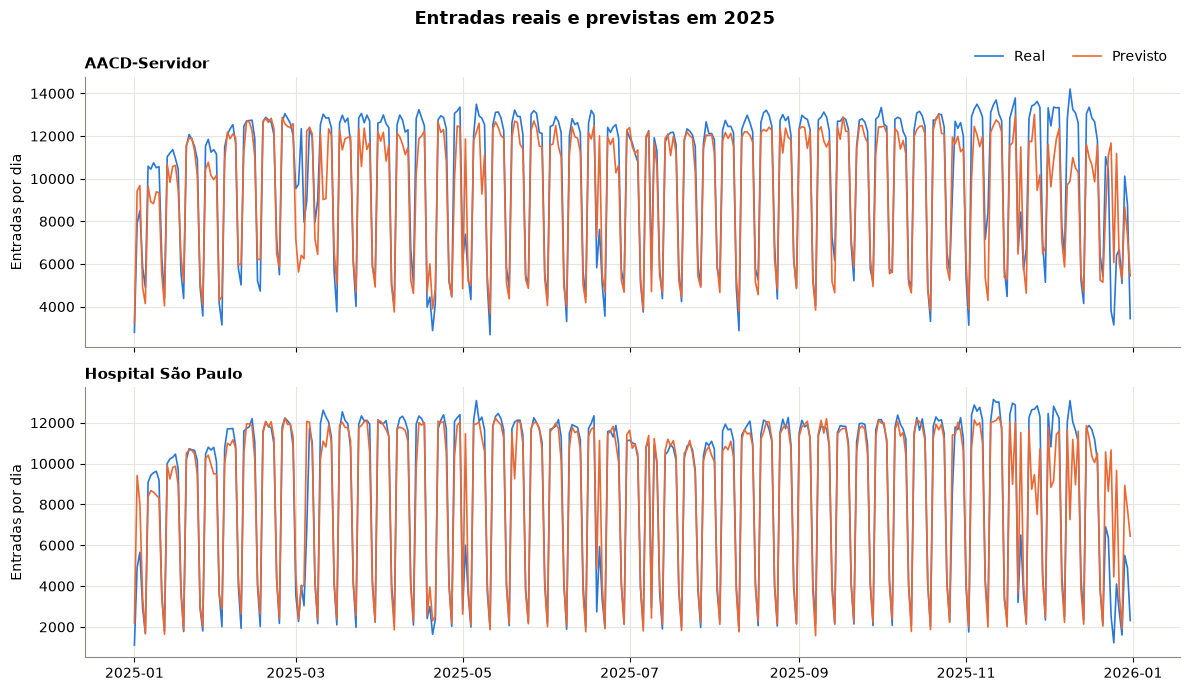

In [25]:
teste_a = teste_a.copy()
teste_a['previsto'] = xgb_a.predict(X_teste_a)

fig, eixos = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for eixo, nome in zip(eixos, ESTACOES):
    dados = teste_a[teste_a['nome_estacao'] == nome]
    eixo.plot(dados['data'], dados['entradas'], color=AZUL, linewidth=1.2, label='Real')
    eixo.plot(dados['data'], dados['previsto'], color=LARANJA, linewidth=1.2, label='Previsto')
    eixo.set_title(nome, loc='left', fontsize=11)
    eixo.set_ylabel('Entradas por dia')
eixos[0].legend(loc='lower right', bbox_to_anchor=(1, 1.0), frameon=False, ncol=2)
fig.suptitle('Entradas reais e previstas em 2025', fontweight='bold', fontsize=13)
fig.tight_layout()
plt.show()

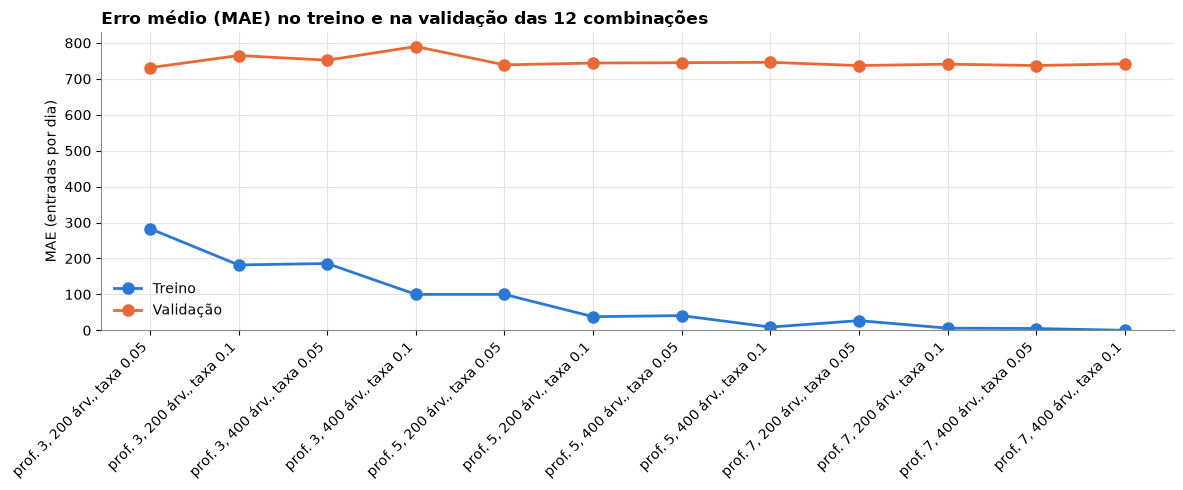

In [26]:
ordem = combinacoes_a.sort_values(['max_depth', 'n_estimators', 'learning_rate']).reset_index(drop=True)
rotulos = [f'prof. {p}, {n} árv., taxa {t}' for p, n, t in zip(ordem['max_depth'], ordem['n_estimators'], ordem['learning_rate'])]

fig, eixo = plt.subplots(figsize=(12, 5))
eixo.plot(rotulos, ordem['MAE treino'], color=AZUL, linewidth=2, marker='o', markersize=8, label='Treino')
eixo.plot(rotulos, ordem['MAE validação'], color=LARANJA, linewidth=2, marker='o', markersize=8, label='Validação')
eixo.set_title('Erro médio (MAE) no treino e na validação das 12 combinações', loc='left')
eixo.set_ylabel('MAE (entradas por dia)')
eixo.set_ylim(bottom=0)
eixo.legend(frameon=False)
plt.xticks(rotation=45, ha='right')
fig.tight_layout()
plt.show()

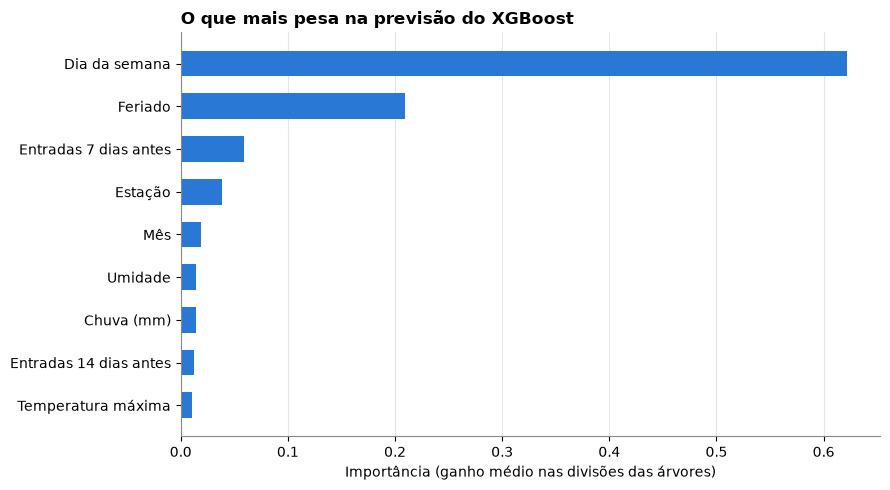

In [27]:
NOMES_VARIAVEIS = {
    'estacao': 'Estação', 'dia_semana': 'Dia da semana', 'mes': 'Mês', 'feriado': 'Feriado',
    'chuva_mm': 'Chuva (mm)', 'temp_max_c': 'Temperatura máxima', 'umidade_pct': 'Umidade',
    'entradas_7d_antes': 'Entradas 7 dias antes', 'entradas_14d_antes': 'Entradas 14 dias antes',
}
importancia = pd.Series(xgb_a.feature_importances_, index=[NOMES_VARIAVEIS[v] for v in VARIAVEIS_A]).sort_values()

fig, eixo = plt.subplots(figsize=(9, 5))
eixo.barh(importancia.index, importancia.values, color=AZUL, height=0.6)
eixo.set_title('O que mais pesa na previsão do XGBoost', loc='left')
eixo.set_xlabel('Importância (ganho médio nas divisões das árvores)')
eixo.grid(axis='y', visible=False)
fig.tight_layout()
plt.show()

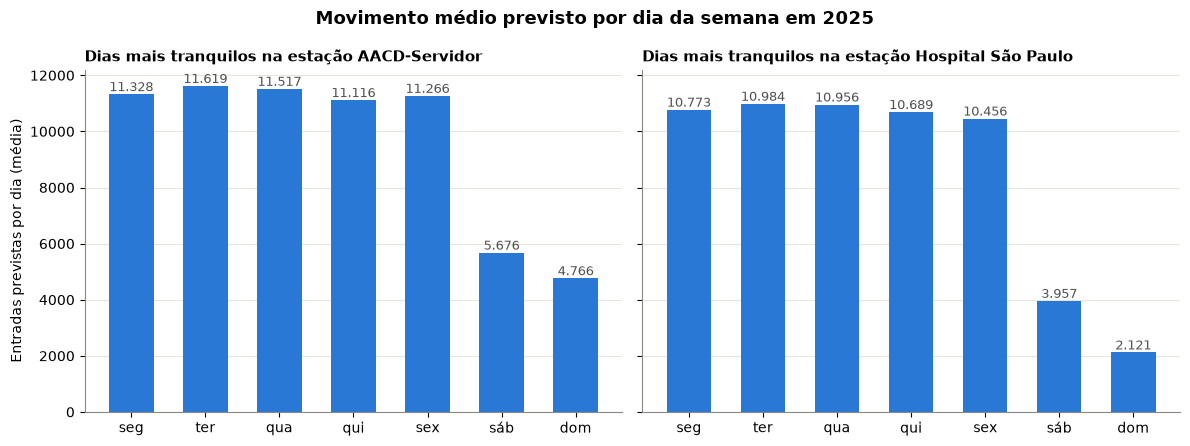

In [28]:
DIAS = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
media_dia = teste_a.groupby(['nome_estacao', 'dia_semana'])['previsto'].mean()

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for eixo, nome in zip(eixos, ESTACOES):
    valores = media_dia[nome]
    eixo.bar(DIAS, valores.values, color=AZUL, width=0.6)
    for x, v in zip(DIAS, valores.values):
        eixo.text(x, v, f'{v:,.0f}'.replace(',', '.'), ha='center', va='bottom', fontsize=9, color='#52514e')
    eixo.set_title(f'Dias mais tranquilos na estação {nome}', loc='left', fontsize=11)
    eixo.grid(axis='x', visible=False)
eixos[0].set_ylabel('Entradas previstas por dia (média)')
fig.suptitle('Movimento médio previsto por dia da semana em 2025', fontweight='bold', fontsize=13)
fig.tight_layout()
plt.show()

Para ver se a chuva muda o movimento, comparamos os dados reais de 2024 e 2025 em dias úteis sem feriado, separando os dias com 10 mm de chuva ou mais dos dias sem chuva.

In [29]:
uteis = tabela[(tabela['dia_semana'] < 5) & (tabela['feriado'] == 0)]
sem_chuva = uteis[uteis['chuva_mm'] == 0]
com_chuva = uteis[uteis['chuva_mm'] >= 10]

linhas = []
for nome in ESTACOES:
    s = sem_chuva[sem_chuva['nome_estacao'] == nome]['entradas']
    c = com_chuva[com_chuva['nome_estacao'] == nome]['entradas']
    linhas.append({
        'estação': nome,
        'dias sem chuva': len(s),
        'média sem chuva': round(s.mean()),
        'dias com 10 mm ou mais': len(c),
        'média com 10 mm ou mais': round(c.mean()),
        'diferença (%)': round((c.mean() / s.mean() - 1) * 100, 1),
    })
pd.DataFrame(linhas)

,estação,dias sem chuva,média sem chuva,dias com 10 mm ou mais,média com 10 mm ou mais,diferença (%)
0,AACD-Servidor,307,12194,73,11517,-5.6
1,Hospital São Paulo,307,11357,73,10812,-4.8


### Conclusão do Modelo A

Sábado e domingo são os dias mais tranquilos nas duas estações. O movimento previsto cai para mais ou menos a metade na AACD-Servidor e para menos de 40% no Hospital São Paulo. Isso quer dizer menos barulho e menos gente para pessoas autistas e para quem usa cadeira de rodas.

Consulta e terapia costumam ser em dia útil. Entre esses dias, o mais tranquilo é a quinta na AACD-Servidor (11.116 entradas previstas) e a sexta no Hospital São Paulo (10.456). Para quem vai a uma consulta, escolher entre os dias úteis muda pouco (menos de 5%). O que mais ajuda é evitar a terça, o dia útil mais cheio nas duas estações.

Em dias úteis com 10 mm de chuva ou mais entram cerca de 5% menos pessoas (5,6% na AACD-Servidor e 4,8% no Hospital São Paulo). Parte disso pode ser efeito das férias de verão, já que esses dias se concentram de dezembro a março.

O modelo erra em média cerca de 760 pessoas por dia, perto de 8% do movimento médio. Ele também tem limites. Prevê o dia e não a hora, e entradas não são o mesmo que lotação dentro da estação. Além disso, a chuva é medida no Mirante de Santana, longe da Vila Clementino, e no app ela viria da previsão do tempo, que também erra.